# ⚡ PowerCast: Forecasting a Household's Electricity Use for the Next 24 Hours

**Team:** Rana Aljumayi · Salwa · Renad Alotaibi · Raneem Alghamdi

**Le Wagon Data Science #2344 · Project Weeks (11–15 Oct 2026)**

## Problem
Households only see their consumption when the bill arrives, and the grid needs to anticipate peak hours.
**Goal:** forecast a home's **hourly electricity consumption for the next 24 hours**, using only data available up to that time, and flag the **expected peak hour**.

| Decision | Choice |
|---|---|
| Dataset | UCI Household Electric Power Consumption (one home in France, 2006-12 → 2010-11) |
| Target (Y) | Next 24 hours of `Global_active_power` (kW) |
| Inputs (X), past | Last 168 hours (7 days): `Global_active_power` (kW) + `is_weekend`, `hour_sin`, `hour_cos` of those hours |
| Inputs (X), future | Calendar of the **next 24 hours**: `is_weekend`, `hour_sin`, `hour_cos` (known in advance, no leakage) |
| Not used | `Global_intensity`, voltage, sub-meters, and any consumption from the forecast period (leakage or unknown at forecast time) |
| Final model | **LSTM V4**: LSTM(32) on the past 168 hours + calendar of the next 24 hours → Dense(24). Lowest validation MAE (section 5h) |
| Time step | 1 hour |
| Horizon | Next 24 hours |
| Main metric | MAE (kW) |
| Extra metrics | RMSE · sMAPE · R² |

## 1. Setup

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = '/content/drive/MyDrive/PowerCast'
SEED = 42
np.random.seed(SEED)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Data Preparation

Raw data: **2,075,259 minute readings** (2006-12-16 → 2010-11-26), from the UCI Household Power Consumption dataset.

**Main steps** (full details in `01_data_cleaning_rana.ipynb`):
1. Combined `Date` + `Time` into one datetime index, sorted, no duplicates.
2. Resampled minutes → **hourly averages** (34,589 hours).
3. Filled 421 missing hours (1.2%):
   - short gaps (≤ 3h) → time interpolation
   - long gaps (14–119h) → same hour from the previous week (past data only)
4. Split **by date** (no shuffle): Train → 2009-12-31 · Validation 2010-01 to 2010-06 · Test 2010-07 → end.

In [ ]:
df = pd.read_csv(f'{BASE}/data/hourly_clean.csv', index_col=0, parse_dates=True)

with open(f'{BASE}/data/split_dates.json') as f:
    splits = json.load(f)

print(df.shape)
print(df['split'].value_counts())
df.head()

(34589, 9)
split
train    26671
val       4344
test      3574
Name: count, dtype: int64


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,was_missing,split
datetime,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,0,train
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,0,train
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,0,train
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,0,train
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,0,train


## 3. Key Findings (EDA)

Full analysis in `02_EDA_salwa.ipynb` (train data only).

- **Daily pattern:** lowest at 03:00 (0.44 kW), highest at 20:00 (1.95 kW).
- **Weekly pattern:** weekends are 22% higher than weekdays (1.26 vs 1.03 kW).
- **Yearly seasonality:** winter is higher (Jan 1.47 kW) than summer (Aug 0.57 kW).
- **Repetition:** autocorrelation peaks at 24h (0.43) and 168h (0.47), so past days and weeks help the forecast.

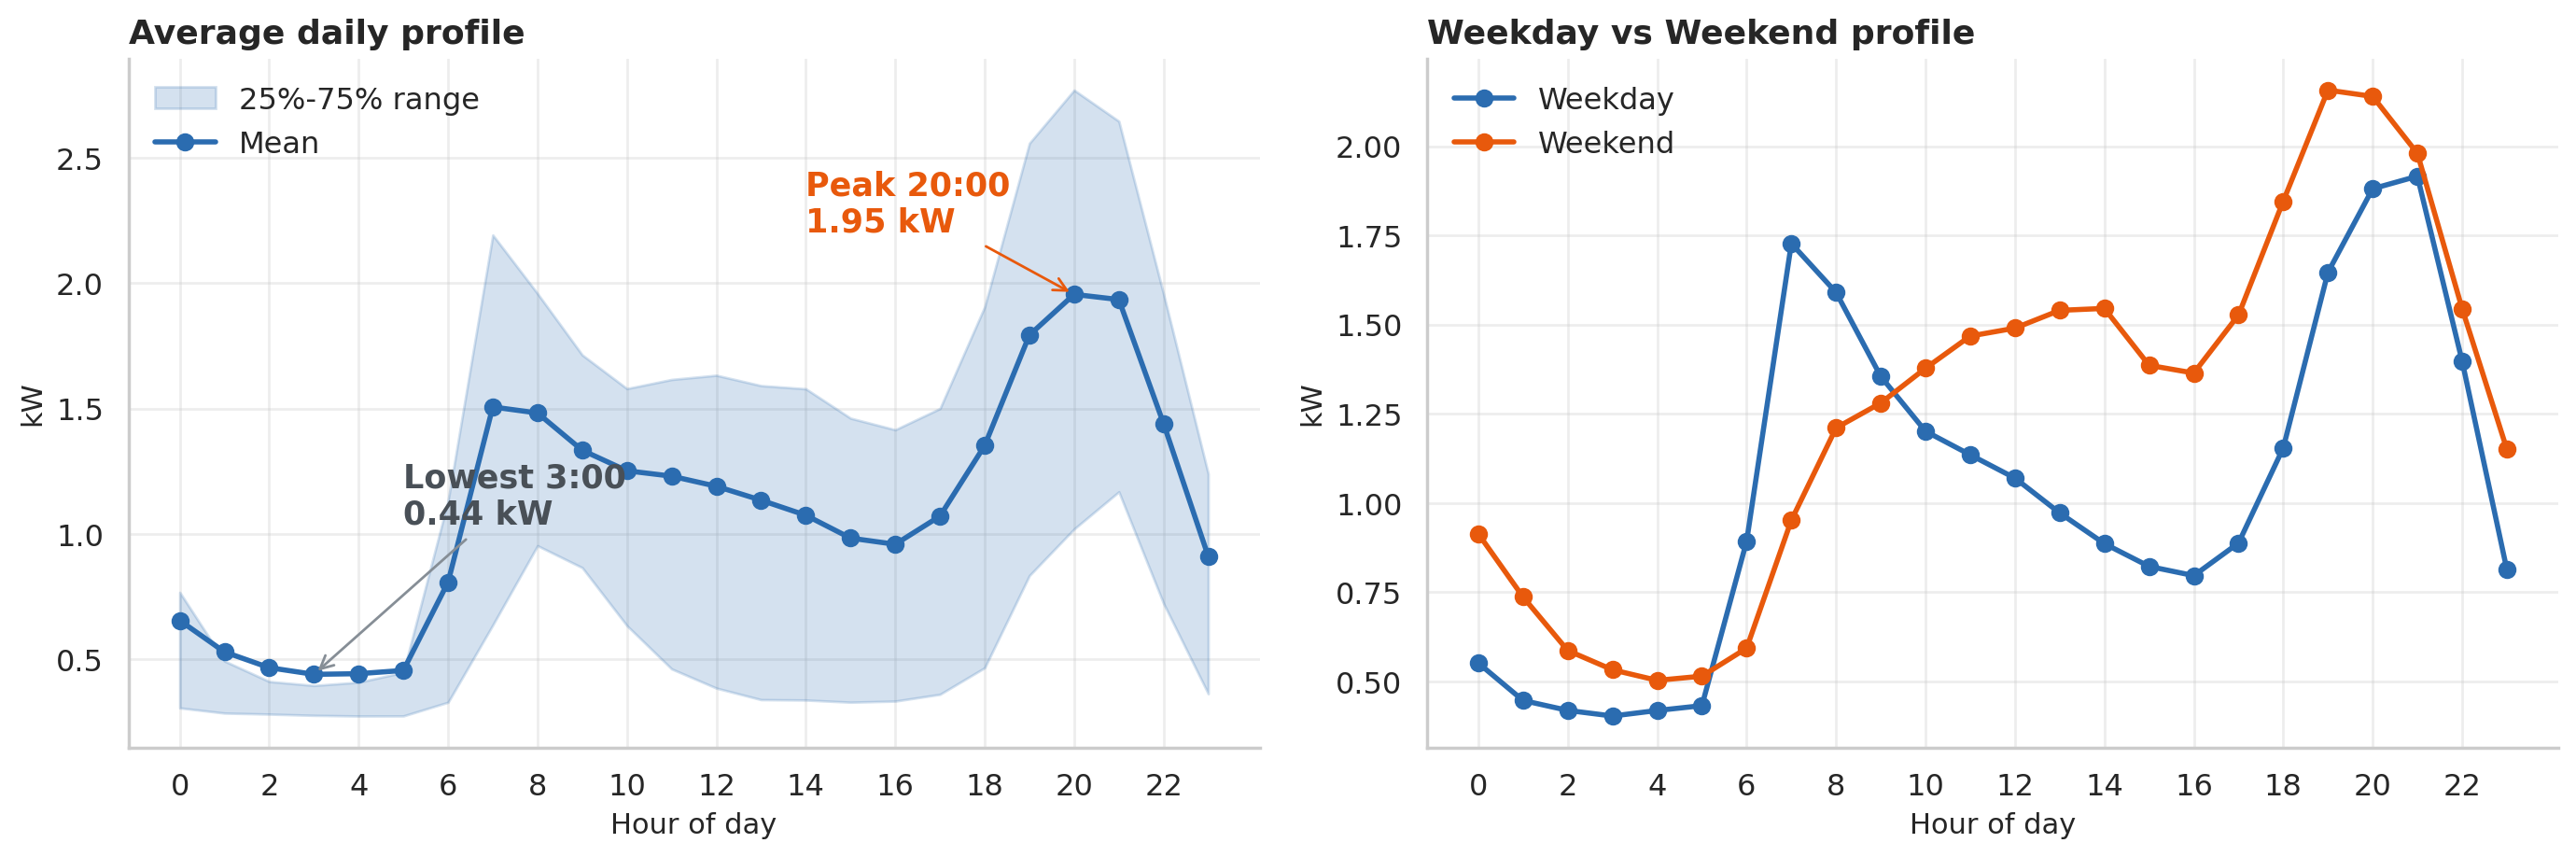

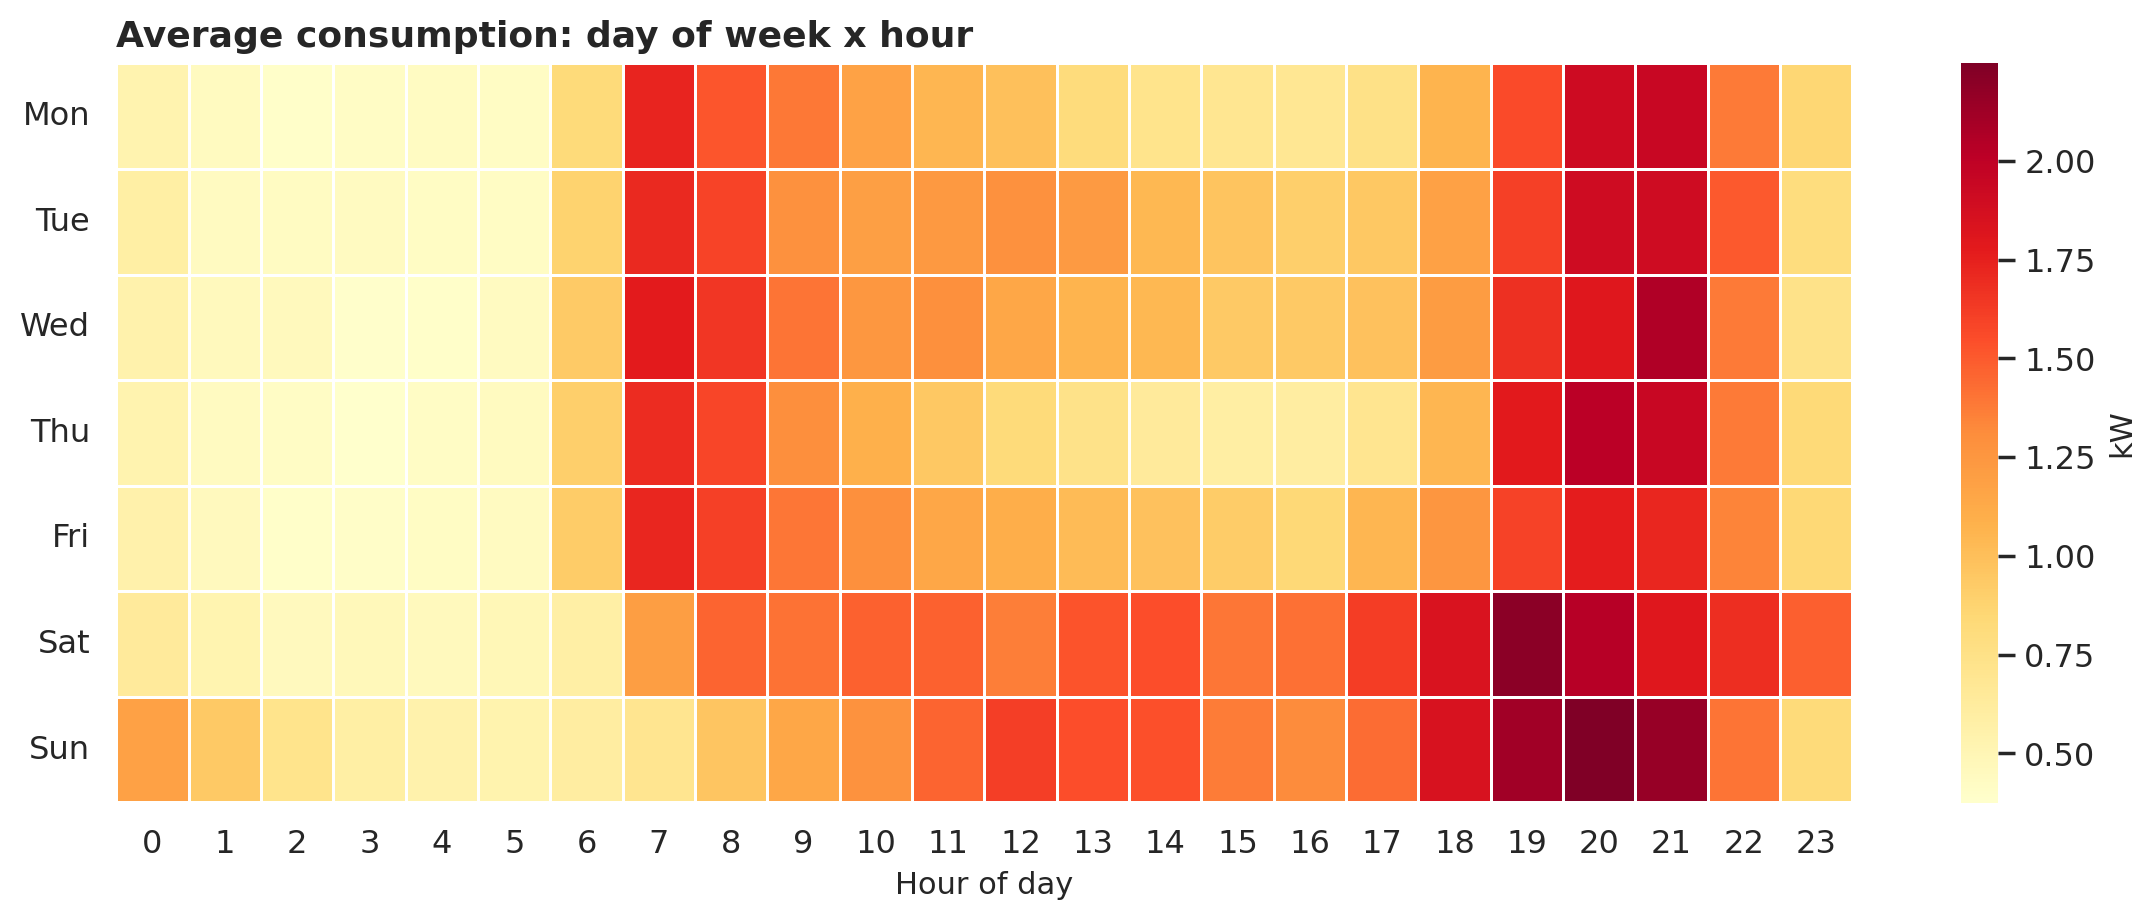

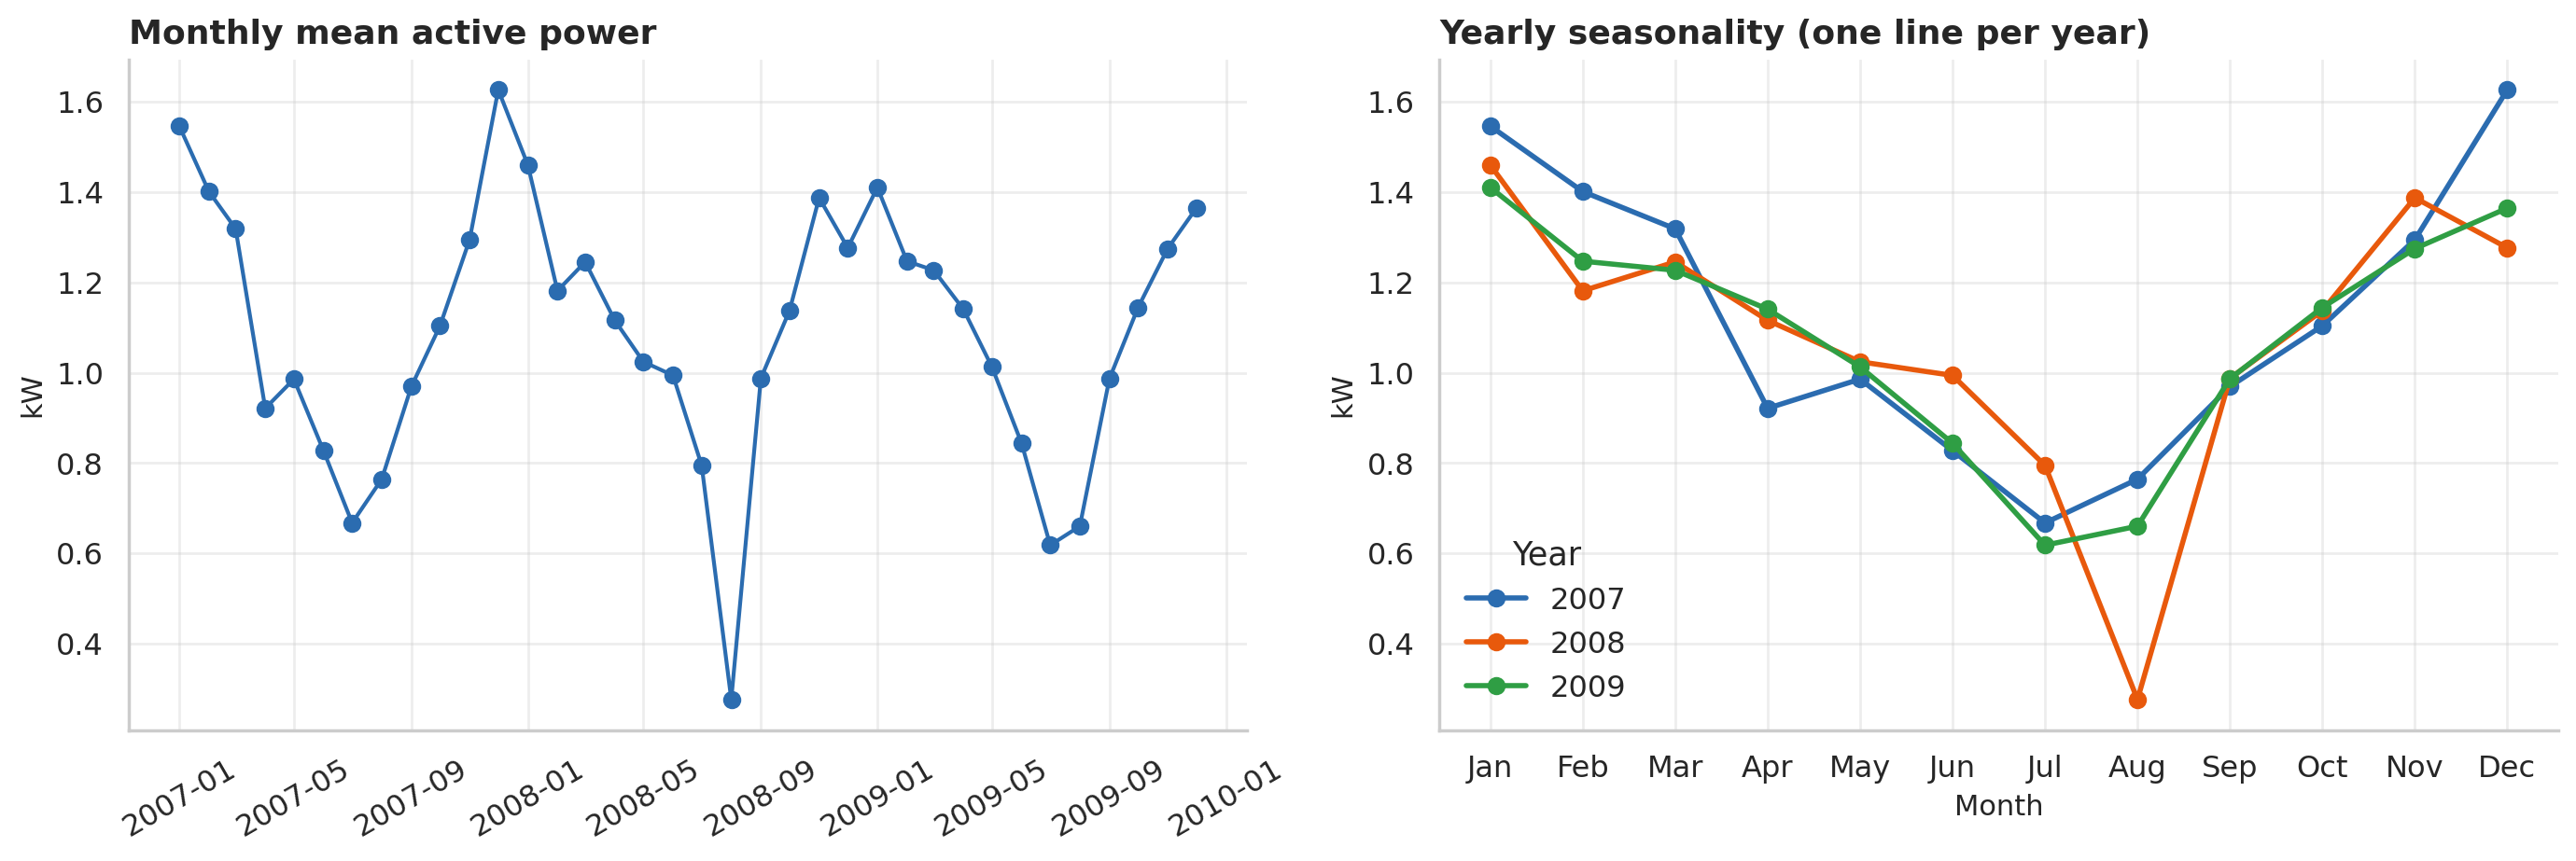

In [ ]:
from IPython.display import Image, display

FIG = f'{BASE}/figures'
for name in ['04_daily_profile', '06_heatmap_day_hour', '03_monthly_seasonality']:
    display(Image(f'{FIG}/{name}.png', width=900))

### 3b. Distribution of Y (TA question)
Is the target skewed? Kernel density of hourly `Global_active_power` on the train data.

Mean: 1.100 kW | Median: 0.793 kW
Skewness: 1.31  (0 = symmetric, > 0 = right-skewed)
Skewness after log1p: 0.56


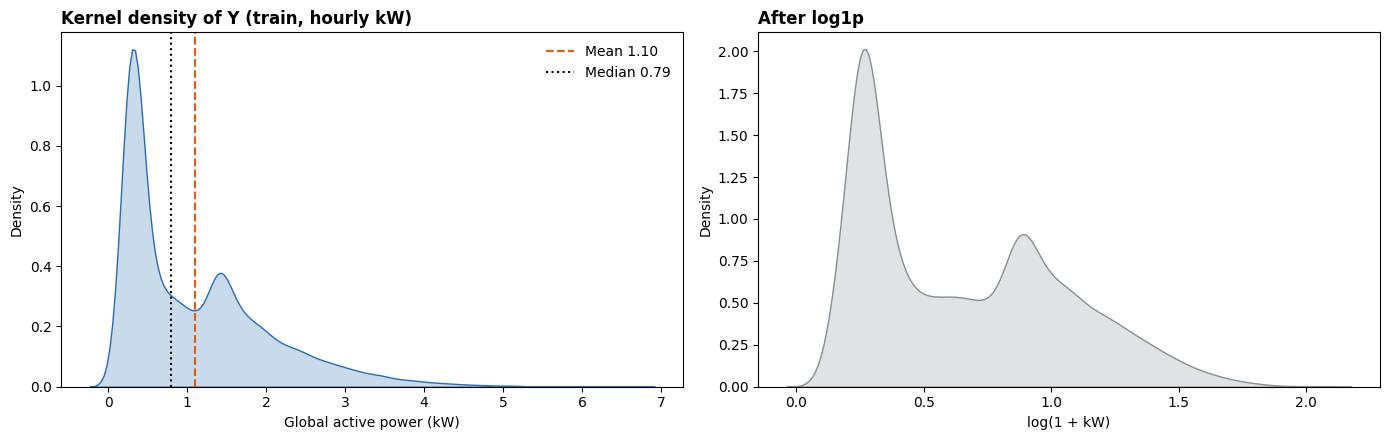

In [ ]:
import seaborn as sns
from scipy.stats import skew

FIG = f'{BASE}/figures'
y_train = df.loc[df['split'] == 'train', 'Global_active_power']

print(f"Mean: {y_train.mean():.3f} kW | Median: {y_train.median():.3f} kW")
print(f"Skewness: {skew(y_train):.2f}  (0 = symmetric, > 0 = right-skewed)")
print(f"Skewness after log1p: {skew(np.log1p(y_train)):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.kdeplot(y_train, fill=True, ax=axes[0], color='#2B6CB0')
axes[0].axvline(y_train.mean(), color='#E8590C', ls='--', label=f'Mean {y_train.mean():.2f}')
axes[0].axvline(y_train.median(), color='black', ls=':', label=f'Median {y_train.median():.2f}')
axes[0].set_title('Kernel density of Y (train, hourly kW)', loc='left', fontweight='bold')
axes[0].set_xlabel('Global active power (kW)')
axes[0].legend(frameon=False)

sns.kdeplot(np.log1p(y_train), fill=True, ax=axes[1], color='#868E96')
axes[1].set_title('After log1p', loc='left', fontweight='bold')
axes[1].set_xlabel('log(1 + kW)')

plt.tight_layout()
plt.savefig(f'{FIG}/y_kde.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Models: Baselines vs LSTM

Full experiments in `03_feature_engineering_modeling_renad.ipynb`. All models forecast the **same validation windows** (168 hours in → 24 hours out, non-overlapping). We change **one thing at a time**:

| Model | How it forecasts the next 24 hours |
|---|---|
| Last-value | Repeat the last observed hour |
| Seasonal Naive | Repeat yesterday (lag 24) |
| Weekly Naive | Repeat the same hours last week (lag 168) |
| LSTM V1 | LSTM(32) + Dense(24), power only, 1,104 daily windows (loaded from `models/`) |
| LSTM V2 | + calendar of the past 168 hours (is_weekend, hour sin/cos), 1,104 daily windows (5d) |
| LSTM V3 | Same as V2, trained on a window starting at **every hour** (~26,000 samples) (5e) |
| LSTM V4 | V3 + calendar of the **next 24 hours** as a second input (5f) |
| LSTM V5 | V4 + **day-of-year** sin/cos (season), in both inputs (5g) |
| **Final model** | The LSTM with the **lowest validation MAE** (5h) |

In [ ]:
TARGET = 'Global_active_power'
HISTORY, HORIZON = 168, 24
y = df[TARGET].to_numpy()
split_arr = df['split'].to_numpy()

def make_windows(split_name):
    pos = np.where(split_arr == split_name)[0]
    starts = list(range(pos[0], pos[-1] + 2 - HORIZON, HORIZON))
    X = np.array([y[s - HISTORY:s] for s in starts])
    Y = np.array([y[s:s + HORIZON] for s in starts])
    return X, Y, df.index[starts]

X_val, Y_val, val_starts = make_windows('val')
print('Validation windows:', X_val.shape, '->', Y_val.shape)
print('Validation hours:', Y_val.size)

Validation windows: (181, 168) -> (181, 24)
Validation hours: 4344


### 4b. Forecasts on Validation
Each model forecasts the same 181 validation windows. LSTM V1 is loaded from Drive with its train-only scaler.

In [ ]:
import joblib
from tensorflow.keras.models import load_model

MODELS = f'{BASE}/models'
lstm = load_model(f'{MODELS}/powercast_lstm.keras', compile=False)
scaler = joblib.load(f'{MODELS}/powercast_scaler.pkl')

def lstm_forecast(X):
    X_scaled = scaler.transform(X.reshape(-1, 1)).reshape(-1, HISTORY, 1)
    pred_scaled = lstm.predict(X_scaled, verbose=0)
    return scaler.inverse_transform(pred_scaled.reshape(-1, 1)).reshape(-1, HORIZON)

def all_forecasts(X):
    return {
        'Last-value':     np.repeat(X[:, -1:], HORIZON, axis=1),
        'Seasonal Naive': X[:, -24:],
        'Weekly Naive':   X[:, :24],
        'LSTM V1':        lstm_forecast(X),
    }

val_preds = all_forecasts(X_val)
for name, P in val_preds.items():
    print(f'{name:15s}', P.shape)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Last-value      (181, 24)
Seasonal Naive  (181, 24)
Weekly Naive    (181, 24)
LSTM V1         (181, 24)


## 5. Results & Error Analysis

### 5a. Model Comparison on Validation
All models are compared on the same 4,344 validation hours, in kW. **MAE is the main metric.**

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def smape(a, p):
    a, p = np.ravel(a), np.ravel(p)
    d = np.abs(a) + np.abs(p)
    return 100 * np.mean(np.divide(2 * np.abs(a - p), d, out=np.zeros_like(d), where=d > 0))

def metrics_table(Y, preds):
    rows = []
    for name, P in preds.items():
        rows.append({
            'Model': name,
            'MAE (kW)': mean_absolute_error(Y.ravel(), P.ravel()),
            'RMSE (kW)': np.sqrt(mean_squared_error(Y.ravel(), P.ravel())),
            'sMAPE (%)': smape(Y, P),
            'R²': r2_score(Y.ravel(), P.ravel()),
        })
    return pd.DataFrame(rows).sort_values('MAE (kW)').reset_index(drop=True)

val_results = metrics_table(Y_val, val_preds)
val_results.round(4)

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
1,Seasonal Naive,0.6153,0.8822,51.6243,-0.1788
2,LSTM V1,0.7199,0.8622,64.2533,-0.1260
3,Last-value,0.7491,1.0077,67.2551,-0.5381


### 5b. Actual vs Forecast (One Validation Week)
Does the forecast follow the daily cycle and the evening peaks?

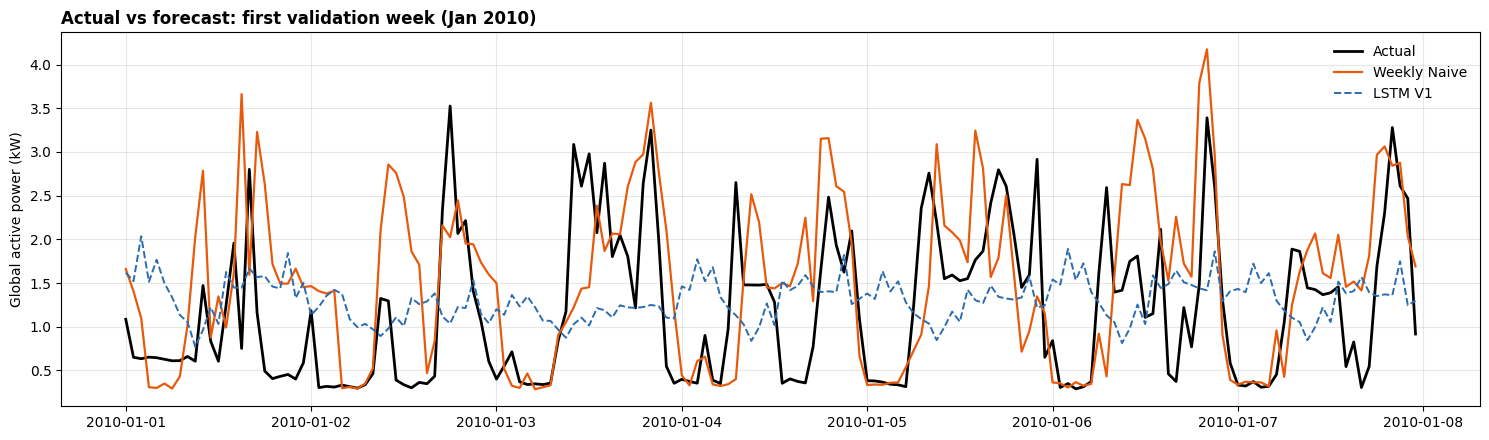

In [ ]:
FIG = f'{BASE}/figures'
WEEK = 7  # 7 windows x 24 hours

times = pd.date_range(val_starts[0], periods=WEEK * HORIZON, freq='h')
actual_week = Y_val[:WEEK].ravel()

plt.figure(figsize=(15, 4.5))
plt.plot(times, actual_week, color='black', lw=2, label='Actual')
plt.plot(times, val_preds['Weekly Naive'][:WEEK].ravel(), color='#E8590C', lw=1.6, label='Weekly Naive')
plt.plot(times, val_preds['LSTM V1'][:WEEK].ravel(), color='#2B6CB0', lw=1.4, ls='--', label='LSTM V1')
plt.title('Actual vs forecast: first validation week (Jan 2010)', loc='left', fontweight='bold')
plt.ylabel('Global active power (kW)')
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5c. Error Analysis
- **Bias:** does the model forecast too high or too low?
- **High-consumption hours:** how big is the error on the top 25% hours?
- **Peak hour:** does it find the hour of the daily peak?
- **Hour of day:** when is the error largest?

,Model,Bias (kW),MAE high hours (kW),Bias high hours (kW),Peak hour exact (%),Peak hour ±1h (%)
0,Weekly Naive,0.026,0.838,-0.548,13.812,29.834
1,Seasonal Naive,0.003,0.896,-0.652,7.182,26.519
2,LSTM V1,0.078,1.045,-1.045,5.525,14.917


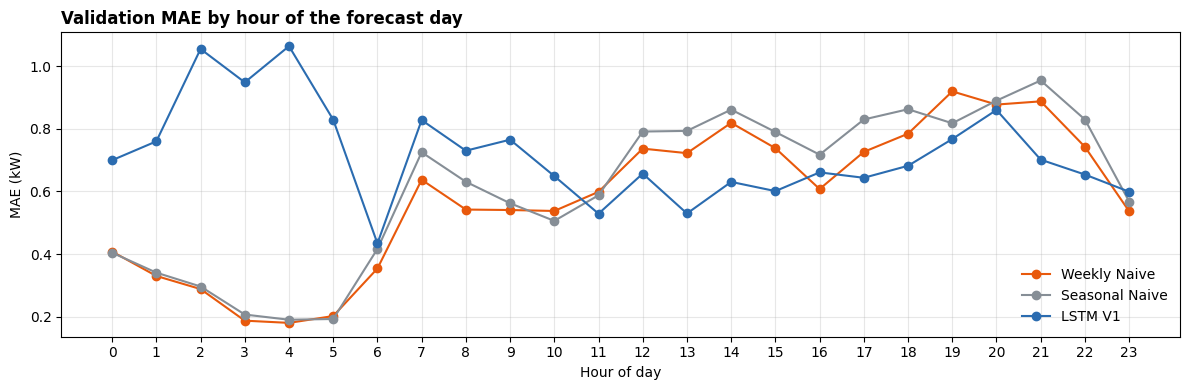

In [ ]:
high = Y_val >= np.percentile(Y_val, 75)
rows = []
for name in ['Weekly Naive', 'Seasonal Naive', 'LSTM V1']:
    P = val_preds[name]
    err = P - Y_val
    rows.append({
        'Model': name,
        'Bias (kW)': err.mean(),
        'MAE high hours (kW)': np.abs(err[high]).mean(),
        'Bias high hours (kW)': err[high].mean(),
        'Peak hour exact (%)': 100 * np.mean(P.argmax(1) == Y_val.argmax(1)),
        'Peak hour ±1h (%)': 100 * np.mean(np.abs(P.argmax(1) - Y_val.argmax(1)) <= 1),
    })
display(pd.DataFrame(rows).round(3))

plt.figure(figsize=(12, 4))
for name, c in [('Weekly Naive', '#E8590C'), ('Seasonal Naive', '#868E96'), ('LSTM V1', '#2B6CB0')]:
    plt.plot(range(24), np.abs(val_preds[name] - Y_val).mean(axis=0), marker='o', color=c, label=name)
plt.title('Validation MAE by hour of the forecast day', loc='left', fontweight='bold')
plt.xlabel('Hour of day')
plt.ylabel('MAE (kW)')
plt.xticks(range(24))
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG}/final_error_by_hour.png', dpi=200, bbox_inches='tight')
plt.show()

### 5d. LSTM V2: adding calendar features (is_weekend, hour sin/cos)
Inputs (X) per hour: power + is_weekend + hour_sin + hour_cos → 168 × 4. Target (Y): next 24h power. Compared on **validation only**.

The helper functions below are shared by V2–V5, so every version is built, trained and evaluated in exactly the same way. Seeds and deterministic mode keep the results the same on every run.

In [ ]:
import warnings
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings('ignore', message='X does not have valid feature names')

if not tf.config.list_physical_devices('GPU'):
    tf.config.experimental.enable_op_determinism()   # same results on every run (CPU)

def reset_seeds(seed=42):
    keras.utils.set_random_seed(seed)                # Python + NumPy + TensorFlow

VAL = [s for s in df['split'].unique() if s not in ('train', 'test')][0]

# 1) Calendar features (known in advance -> no leakage)
df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)
df['hour_sin'] = np.sin(2 * np.pi * df.index.hour / 24)
df['hour_cos'] = np.cos(2 * np.pi * df.index.hour / 24)
CAL3 = ['is_weekend', 'hour_sin', 'hour_cos']

# 2) Scale power on TRAIN only
p_scaler = StandardScaler().fit(df.loc[df['split'] == 'train', [TARGET]])
power_s = p_scaler.transform(df[[TARGET]]).ravel()

# 3) Helpers shared by V2-V5
def get_starts(split_name, stride):
    """Position of the first forecast hour of each window (the 24 target hours stay inside the split)."""
    pos = np.where(split_arr == split_name)[0]
    return np.arange(max(pos[0], HISTORY), pos[-1] + 2 - HORIZON, stride)

def make_spec(past_cols, fut_cols=None):
    """past: power + calendar of the past hours | fut: calendar of the next 24 hours (or None)."""
    past = np.column_stack([power_s, df[past_cols].to_numpy()]).astype('float32')
    fut = None if fut_cols is None else df[fut_cols].to_numpy('float32')
    return {'past': past, 'fut': fut, 'past_cols': past_cols, 'fut_cols': fut_cols}

def make_xy(spec, starts):
    X = np.stack([spec['past'][s - HISTORY:s] for s in starts])               # (n, 168, features)
    if spec['fut'] is not None:
        X = [X, np.stack([spec['fut'][s:s + HORIZON] for s in starts])]       # + (n, 24, calendar)
    Y = np.stack([power_s[s:s + HORIZON] for s in starts])                    # (n, 24) scaled
    return X, Y

def lstm_predict(spec, starts):
    X, _ = make_xy(spec, starts)
    pred = spec['model'].predict(X, verbose=0).reshape(-1, 1)
    return p_scaler.inverse_transform(pred).reshape(-1, HORIZON)              # back to kW

def train_lstm(spec, train_stride, epochs=20, batch_size=128, patience=3):
    reset_seeds()
    inp_past = keras.Input(shape=(HISTORY, spec['past'].shape[1]))
    h = keras.layers.LSTM(32)(inp_past)                                      # reads the past 168 hours
    inputs = inp_past
    if spec['fut'] is not None:                                              # V4/V5: add the next-24h calendar
        inp_fut = keras.Input(shape=(HORIZON, spec['fut'].shape[1]))
        h = keras.layers.Concatenate()([h, keras.layers.Flatten()(inp_fut)])
        inputs = [inp_past, inp_fut]
    model = keras.Model(inputs, keras.layers.Dense(HORIZON)(h))
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    X_tr, Y_tr = make_xy(spec, get_starts('train', train_stride))
    X_va, Y_va = make_xy(spec, get_starts(VAL, HORIZON))
    print('Train windows:', len(Y_tr), '| Validation windows:', len(Y_va))
    hist = model.fit(X_tr, Y_tr, validation_data=(X_va, Y_va), epochs=epochs, batch_size=batch_size,
                     callbacks=[keras.callbacks.EarlyStopping(patience=patience, restore_best_weights=True)],
                     verbose=2)
    print('Best epoch:', int(np.argmin(hist.history['val_loss'])) + 1)
    spec['model'] = model
    return spec

val_idx = get_starts(VAL, HORIZON)
assert (df.index[val_idx] == val_starts).all()      # same 181 validation days as the baselines

# 4) LSTM V2: one window per day (1,104 samples)
LSTMS, lstm_val = {}, {}
LSTMS['LSTM V2'] = train_lstm(make_spec(CAL3), train_stride=HORIZON, epochs=50, batch_size=32, patience=5)
lstm_val['LSTM V2'] = lstm_predict(LSTMS['LSTM V2'], val_idx)

metrics_table(Y_val, {'Weekly Naive': val_preds['Weekly Naive'], 'LSTM V1': val_preds['LSTM V1'],
                      **lstm_val}).round(4)

Train windows: 1104 | Validation windows: 181
Epoch 1/50
35/35 - 8s - 218ms/step - loss: 0.9156 - mae: 0.7547 - val_loss: 0.9227 - val_mae: 0.8015
Epoch 2/50
35/35 - 6s - 176ms/step - loss: 0.7193 - mae: 0.6357 - val_loss: 1.2749 - val_mae: 0.9460
Epoch 3/50
35/35 - 4s - 108ms/step - loss: 0.6502 - mae: 0.5937 - val_loss: 1.1928 - val_mae: 0.9089
Epoch 4/50
35/35 - 5s - 131ms/step - loss: 0.6262 - mae: 0.5754 - val_loss: 1.1960 - val_mae: 0.9078
Epoch 5/50
35/35 - 4s - 125ms/step - loss: 0.6196 - mae: 0.5704 - val_loss: 1.1923 - val_mae: 0.9053
Epoch 6/50
35/35 - 2s - 44ms/step - loss: 0.6149 - mae: 0.5668 - val_loss: 1.1874 - val_mae: 0.9021
Best epoch: 1


,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
1,LSTM V1,0.7199,0.8622,64.2533,-0.1260
2,LSTM V2,0.7435,0.8910,66.5900,-0.2025


### 5e. LSTM V3: same 4 features, trained on every hour (overlapping windows)
V2 had only 1,104 training windows, all starting at 17:00, while validation windows start at 00:00. V3 uses a window starting at **every hour** of the train period (~26,000 samples). Validation windows stay the same (181 days).

In [ ]:
LSTMS['LSTM V3'] = train_lstm(make_spec(CAL3), train_stride=1)
lstm_val['LSTM V3'] = lstm_predict(LSTMS['LSTM V3'], val_idx)

metrics_table(Y_val, {'Weekly Naive': val_preds['Weekly Naive'], **lstm_val}).round(4)

Train windows: 26480 | Validation windows: 181
Epoch 1/20
207/207 - 15s - 74ms/step - loss: 0.8143 - mae: 0.6974 - val_loss: 0.5481 - val_mae: 0.5613
Epoch 2/20
207/207 - 13s - 65ms/step - loss: 0.6476 - mae: 0.5933 - val_loss: 0.5130 - val_mae: 0.5385
Epoch 3/20
207/207 - 13s - 65ms/step - loss: 0.6263 - mae: 0.5802 - val_loss: 0.5062 - val_mae: 0.5330
Epoch 4/20
207/207 - 14s - 68ms/step - loss: 0.6161 - mae: 0.5731 - val_loss: 0.5032 - val_mae: 0.5285
Epoch 5/20
207/207 - 13s - 65ms/step - loss: 0.6074 - mae: 0.5669 - val_loss: 0.4996 - val_mae: 0.5247
Epoch 6/20
207/207 - 13s - 64ms/step - loss: 0.6002 - mae: 0.5617 - val_loss: 0.4968 - val_mae: 0.5209
Epoch 7/20
207/207 - 16s - 76ms/step - loss: 0.5945 - mae: 0.5575 - val_loss: 0.4953 - val_mae: 0.5179
Epoch 8/20
207/207 - 19s - 90ms/step - loss: 0.5898 - mae: 0.5541 - val_loss: 0.4948 - val_mae: 0.5160
Epoch 9/20
207/207 - 14s - 65ms/step - loss: 0.5858 - mae: 0.5512 - val_loss: 0.4924 - val_mae: 0.5141
Epoch 10/20
207/207 - 14s 

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,LSTM V3,0.4740,0.6466,43.5107,0.3667
1,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
2,LSTM V2,0.7435,0.8910,66.5900,-0.2025


### 5f. LSTM V4: + calendar of the forecast day (TA feedback)
V3 only sees the calendar of the **past** 168 hours. When we forecast tomorrow, we already know tomorrow's calendar (e.g. *tomorrow is Saturday* → `is_weekend = 1` for its 24 hours). V4 gets it as a **second input**:
- Input 1: past 168 hours × (power + is_weekend + hour sin/cos) → LSTM(32)
- Input 2: next 24 hours × (is_weekend + hour sin/cos) → joined with the LSTM output → Dense(24)

Only the calendar of the future is used, never its consumption → **no leakage**.

In [ ]:
LSTMS['LSTM V4'] = train_lstm(make_spec(CAL3, fut_cols=CAL3), train_stride=1)
lstm_val['LSTM V4'] = lstm_predict(LSTMS['LSTM V4'], val_idx)

metrics_table(Y_val, {'Weekly Naive': val_preds['Weekly Naive'], **lstm_val}).round(4)

Train windows: 26480 | Validation windows: 181
Epoch 1/20
207/207 - 16s - 76ms/step - loss: 0.8330 - mae: 0.7034 - val_loss: 0.5566 - val_mae: 0.5805
Epoch 2/20
207/207 - 14s - 68ms/step - loss: 0.6454 - mae: 0.5920 - val_loss: 0.5108 - val_mae: 0.5366
Epoch 3/20
207/207 - 14s - 66ms/step - loss: 0.6195 - mae: 0.5757 - val_loss: 0.4999 - val_mae: 0.5288
Epoch 4/20
207/207 - 14s - 66ms/step - loss: 0.6068 - mae: 0.5674 - val_loss: 0.4919 - val_mae: 0.5225
Epoch 5/20
207/207 - 14s - 66ms/step - loss: 0.5977 - mae: 0.5613 - val_loss: 0.4860 - val_mae: 0.5167
Epoch 6/20
207/207 - 13s - 65ms/step - loss: 0.5904 - mae: 0.5563 - val_loss: 0.4823 - val_mae: 0.5122
Epoch 7/20
207/207 - 13s - 65ms/step - loss: 0.5844 - mae: 0.5520 - val_loss: 0.4804 - val_mae: 0.5092
Epoch 8/20
207/207 - 21s - 102ms/step - loss: 0.5794 - mae: 0.5484 - val_loss: 0.4764 - val_mae: 0.5059
Epoch 9/20
207/207 - 14s - 66ms/step - loss: 0.5756 - mae: 0.5456 - val_loss: 0.4718 - val_mae: 0.5044
Epoch 10/20
207/207 - 22s

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,LSTM V4,0.4637,0.6326,42.3545,0.3939
1,LSTM V3,0.4740,0.6466,43.5107,0.3667
2,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
3,LSTM V2,0.7435,0.8910,66.5900,-0.2025


### 5g. LSTM V5: + day-of-year sine/cosine (TA feedback)
Same as V4, plus the **season of the year** (winter is higher than summer, see EDA):
`doy_sin = sin(2π · day_of_year / 365.25)`, `doy_cos = cos(2π · day_of_year / 365.25)`.
Added to both inputs: past 168 hours × 6 features, next 24 hours × 5 calendar features.

In [ ]:
df['doy_sin'] = np.sin(2 * np.pi * df.index.dayofyear / 365.25)
df['doy_cos'] = np.cos(2 * np.pi * df.index.dayofyear / 365.25)
CAL5 = CAL3 + ['doy_sin', 'doy_cos']

LSTMS['LSTM V5'] = train_lstm(make_spec(CAL5, fut_cols=CAL5), train_stride=1)
lstm_val['LSTM V5'] = lstm_predict(LSTMS['LSTM V5'], val_idx)

metrics_table(Y_val, {'Weekly Naive': val_preds['Weekly Naive'], **lstm_val}).round(4)

Train windows: 26480 | Validation windows: 181
Epoch 1/20
207/207 - 18s - 89ms/step - loss: 0.8404 - mae: 0.7058 - val_loss: 0.5309 - val_mae: 0.5660
Epoch 2/20
207/207 - 19s - 92ms/step - loss: 0.6266 - mae: 0.5841 - val_loss: 0.4957 - val_mae: 0.5348
Epoch 3/20
207/207 - 20s - 98ms/step - loss: 0.6004 - mae: 0.5659 - val_loss: 0.4815 - val_mae: 0.5217
Epoch 4/20
207/207 - 20s - 94ms/step - loss: 0.5842 - mae: 0.5547 - val_loss: 0.4713 - val_mae: 0.5124
Epoch 5/20
207/207 - 14s - 66ms/step - loss: 0.5704 - mae: 0.5449 - val_loss: 0.4690 - val_mae: 0.5083
Epoch 6/20
207/207 - 20s - 99ms/step - loss: 0.5613 - mae: 0.5385 - val_loss: 0.4722 - val_mae: 0.5100
Epoch 7/20
207/207 - 14s - 67ms/step - loss: 0.5540 - mae: 0.5336 - val_loss: 0.4666 - val_mae: 0.5056
Epoch 8/20
207/207 - 21s - 100ms/step - loss: 0.5489 - mae: 0.5306 - val_loss: 0.4723 - val_mae: 0.5104
Epoch 9/20
207/207 - 14s - 69ms/step - loss: 0.5438 - mae: 0.5275 - val_loss: 0.4707 - val_mae: 0.5094
Epoch 10/20
207/207 - 14s

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,LSTM V4,0.4637,0.6326,42.3545,0.3939
1,LSTM V5,0.4690,0.6336,42.9103,0.3919
2,LSTM V3,0.4740,0.6466,43.5107,0.3667
3,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
4,LSTM V2,0.7435,0.8910,66.5900,-0.2025


### 5h. Choosing the Final Model (validation only)
All models on the same 181 validation days. The final model is the LSTM with the **lowest validation MAE**. It is saved with its scaler and its feature list, so `predict.py` and the dashboard use exactly this model.

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,LSTM V4,0.4637,0.6326,42.3545,0.3939
1,LSTM V5,0.4690,0.6336,42.9103,0.3919
2,LSTM V3,0.4740,0.6466,43.5107,0.3667
3,Weekly Naive,0.5796,0.8392,49.1379,-0.0666
4,Seasonal Naive,0.6153,0.8822,51.6243,-0.1788
5,LSTM V1,0.7199,0.8622,64.2533,-0.1260
6,LSTM V2,0.7435,0.8910,66.5900,-0.2025
7,Last-value,0.7491,1.0077,67.2551,-0.5381


Final model (lowest validation MAE): LSTM V4
Saved: models/powercast_lstm_final.keras + powercast_scaler_final.pkl + powercast_final_config.json


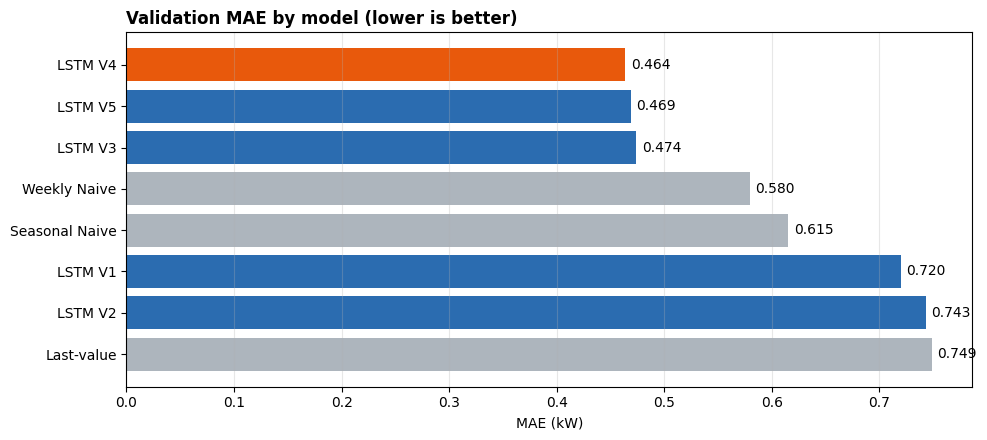

In [ ]:
selection = metrics_table(Y_val, {**{n: val_preds[n] for n in ['Weekly Naive', 'Seasonal Naive', 'Last-value', 'LSTM V1']},
                                  **lstm_val})
display(selection.round(4))

FINAL = min(lstm_val, key=lambda n: mean_absolute_error(Y_val.ravel(), lstm_val[n].ravel()))
FINAL_LABEL = f'{FINAL} (final)'
val_preds[FINAL_LABEL] = lstm_val[FINAL]
print('Final model (lowest validation MAE):', FINAL)

# Save model + scaler + feature list for predict.py and the dashboard
spec = LSTMS[FINAL]
spec['model'].save(f'{MODELS}/powercast_lstm_final.keras')
joblib.dump(p_scaler, f'{MODELS}/powercast_scaler_final.pkl')
with open(f'{MODELS}/powercast_final_config.json', 'w') as f:
    json.dump({'model': FINAL, 'history': HISTORY, 'horizon': HORIZON,
               'past_cols': spec['past_cols'], 'fut_cols': spec['fut_cols']}, f, indent=2)
print('Saved: models/powercast_lstm_final.keras + powercast_scaler_final.pkl + powercast_final_config.json')

# Bar chart for the slides
order = selection.sort_values('MAE (kW)', ascending=False)
colors = ['#E8590C' if m == FINAL else ('#2B6CB0' if m.startswith('LSTM') else '#ADB5BD') for m in order['Model']]
plt.figure(figsize=(10, 4.5))
plt.barh(order['Model'], order['MAE (kW)'], color=colors)
for i, v in enumerate(order['MAE (kW)']):
    plt.text(v + 0.005, i, f'{v:.3f}', va='center')
plt.title('Validation MAE by model (lower is better)', loc='left', fontweight='bold')
plt.xlabel('MAE (kW)')
plt.grid(alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig(f'{FIG}/final_model_comparison.png', dpi=200, bbox_inches='tight')
plt.show()

**Result:** **LSTM V4 is the final model** (validation MAE **0.464 kW**, −20% vs Weekly Naive, R² +0.39).
- V2 → V3: training on a window at every hour made the biggest difference (0.744 → 0.474).
- V3 → V4: giving the model the **calendar of the next 24 hours** improved it again (0.474 → 0.464).
- V4 → V5: adding **day of year** did not help (0.469). The last 7 days already tell the model the level of the current season, so we kept the simpler V4.

### 5i. Final Model Check: Week Plot & Error Analysis
Same week plot and error analysis as 5b–5c, now with the final model.

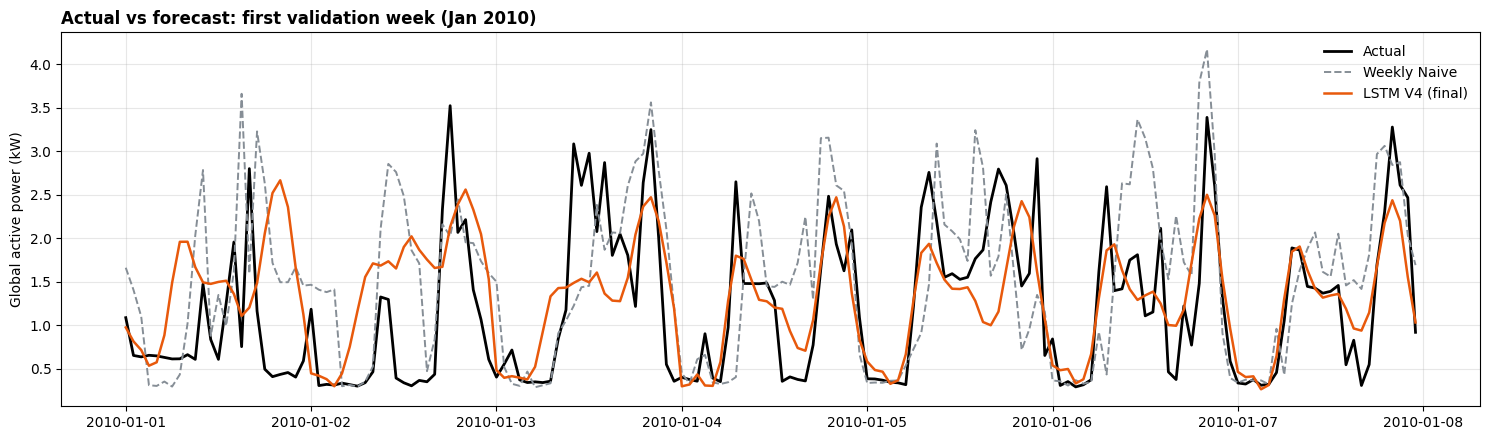

,Model,Bias (kW),MAE high hours (kW),Bias high hours (kW),Peak hour exact (%),Peak hour ±1h (%)
0,LSTM V4 (final),-0.039,0.719,-0.668,18.785,39.779
1,Weekly Naive,0.026,0.838,-0.548,13.812,29.834
2,Seasonal Naive,0.003,0.896,-0.652,7.182,26.519
3,LSTM V1,0.078,1.045,-1.045,5.525,14.917


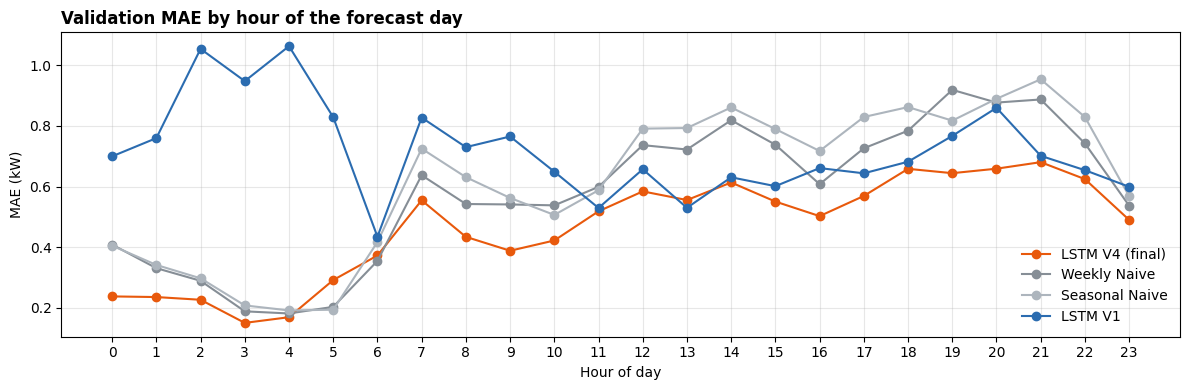

In [ ]:
P_final = val_preds[FINAL_LABEL]

# 1) One validation week
plt.figure(figsize=(15, 4.5))
plt.plot(times, actual_week, color='black', lw=2, label='Actual')
plt.plot(times, val_preds['Weekly Naive'][:WEEK].ravel(), color='#868E96', lw=1.4, ls='--', label='Weekly Naive')
plt.plot(times, P_final[:WEEK].ravel(), color='#E8590C', lw=1.8, label=FINAL_LABEL)
plt.title('Actual vs forecast: first validation week (Jan 2010)', loc='left', fontweight='bold')
plt.ylabel('Global active power (kW)')
plt.legend(frameon=False); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{FIG}/final_actual_vs_forecast_week.png', dpi=200, bbox_inches='tight')
plt.show()

# 2) Error analysis table
rows = []
for name in [FINAL_LABEL, 'Weekly Naive', 'Seasonal Naive', 'LSTM V1']:
    P = val_preds[name]; err = P - Y_val
    rows.append({
        'Model': name,
        'Bias (kW)': err.mean(),
        'MAE high hours (kW)': np.abs(err[high]).mean(),
        'Bias high hours (kW)': err[high].mean(),
        'Peak hour exact (%)': 100 * np.mean(P.argmax(1) == Y_val.argmax(1)),
        'Peak hour ±1h (%)': 100 * np.mean(np.abs(P.argmax(1) - Y_val.argmax(1)) <= 1),
    })
err_table = pd.DataFrame(rows)
display(err_table.round(3))

# 3) MAE by hour of day
plt.figure(figsize=(12, 4))
for name, c in [(FINAL_LABEL, '#E8590C'), ('Weekly Naive', '#868E96'), ('Seasonal Naive', '#ADB5BD'), ('LSTM V1', '#2B6CB0')]:
    plt.plot(range(24), np.abs(val_preds[name] - Y_val).mean(axis=0), marker='o', color=c, label=name)
plt.title('Validation MAE by hour of the forecast day', loc='left', fontweight='bold')
plt.xlabel('Hour of day'); plt.ylabel('MAE (kW)'); plt.xticks(range(24))
plt.legend(frameon=False); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{FIG}/final_error_by_hour.png', dpi=200, bbox_inches='tight')
plt.show()

### 5j. Extra experiment: LSTM V6 trained on log1p(Y) (TA feedback)
Y is right-skewed (section 3b). V6 is **V4 with one change**: the target is `log1p(Y)` (scaled on train only), and the forecast is converted back to kW with `expm1`. Compared on **validation only**. V4 is loaded from `models/` (no retraining).

In [ ]:
from tensorflow.keras.models import load_model
reset_seeds()

# Target in log space (scaler fitted on train only)
log_y = np.log1p(df[TARGET].to_numpy())
log_scaler = StandardScaler().fit(log_y[split_arr == 'train'].reshape(-1, 1))
log_s = log_scaler.transform(log_y.reshape(-1, 1)).ravel()

spec6 = make_spec(CAL3, fut_cols=CAL3)            # same inputs as V4
def xy_log(starts):
    X, _ = make_xy(spec6, starts)
    Y = np.stack([log_s[s:s + HORIZON] for s in starts])
    return X, Y

X_tr6, Y_tr6 = xy_log(get_starts('train', 1))
X_va6, Y_va6 = xy_log(val_idx)

# Same architecture as V4
inp_past = keras.Input(shape=(HISTORY, spec6['past'].shape[1]))
inp_fut = keras.Input(shape=(HORIZON, spec6['fut'].shape[1]))
h = keras.layers.Concatenate()([keras.layers.LSTM(32)(inp_past), keras.layers.Flatten()(inp_fut)])
model_v6 = keras.Model([inp_past, inp_fut], keras.layers.Dense(HORIZON)(h))
model_v6.compile(optimizer='adam', loss='mse', metrics=['mae'])
hist6 = model_v6.fit(X_tr6, Y_tr6, validation_data=(X_va6, Y_va6), epochs=20, batch_size=128,
                     callbacks=[keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True)], verbose=2)
print('Best epoch:', int(np.argmin(hist6.history['val_loss'])) + 1)

# Back to kW
pred_v6 = np.expm1(log_scaler.inverse_transform(model_v6.predict(X_va6, verbose=0).reshape(-1, 1))).reshape(-1, HORIZON)

# V4 = the saved final model (no retraining)
spec4 = make_spec(CAL3, fut_cols=CAL3)
spec4['model'] = load_model(f'{MODELS}/powercast_lstm_final.keras', compile=False)
pred_v4 = lstm_predict(spec4, val_idx)

# Compare on validation
v6_preds = {'Weekly Naive': val_preds['Weekly Naive'],
            'LSTM V4 (final)': pred_v4,
            'LSTM V6 (log1p Y)': pred_v6}
display(metrics_table(Y_val, v6_preds).round(4))

high = Y_val >= np.percentile(Y_val, 75)
rows = []
for name, P in v6_preds.items():
    err = P - Y_val
    rows.append({'Model': name,
                 'Bias (kW)': err.mean(),
                 'MAE high hours (kW)': np.abs(err[high]).mean(),
                 'Bias high hours (kW)': err[high].mean(),
                 'Peak hour exact (%)': 100 * np.mean(P.argmax(1) == Y_val.argmax(1)),
                 'Peak hour ±1h (%)': 100 * np.mean(np.abs(P.argmax(1) - Y_val.argmax(1)) <= 1)})
display(pd.DataFrame(rows).round(3))

Epoch 1/20
207/207 - 17s - 81ms/step - loss: 0.8154 - mae: 0.7502 - val_loss: 0.5462 - val_mae: 0.6110
Epoch 2/20
207/207 - 13s - 65ms/step - loss: 0.6067 - mae: 0.6173 - val_loss: 0.5062 - val_mae: 0.5659
Epoch 3/20
207/207 - 13s - 63ms/step - loss: 0.5790 - mae: 0.5977 - val_loss: 0.4905 - val_mae: 0.5547
Epoch 4/20
207/207 - 21s - 103ms/step - loss: 0.5649 - mae: 0.5878 - val_loss: 0.4783 - val_mae: 0.5448
Epoch 5/20
207/207 - 21s - 101ms/step - loss: 0.5559 - mae: 0.5815 - val_loss: 0.4728 - val_mae: 0.5401
Epoch 6/20
207/207 - 20s - 97ms/step - loss: 0.5490 - mae: 0.5767 - val_loss: 0.4697 - val_mae: 0.5373
Epoch 7/20
207/207 - 14s - 66ms/step - loss: 0.5431 - mae: 0.5726 - val_loss: 0.4680 - val_mae: 0.5353
Epoch 8/20
207/207 - 21s - 103ms/step - loss: 0.5378 - mae: 0.5689 - val_loss: 0.4684 - val_mae: 0.5348
Epoch 9/20
207/207 - 20s - 95ms/step - loss: 0.5327 - mae: 0.5654 - val_loss: 0.4700 - val_mae: 0.5357
Epoch 10/20
207/207 - 14s - 67ms/step - loss: 0.5281 - mae: 0.5622 - v

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,LSTM V4 (final),0.4637,0.6326,42.3545,0.3939
1,LSTM V6 (log1p Y),0.4703,0.6486,43.0562,0.3629
2,Weekly Naive,0.5796,0.8392,49.1379,-0.0666


,Model,Bias (kW),MAE high hours (kW),Bias high hours (kW),Peak hour exact (%),Peak hour ±1h (%)
0,Weekly Naive,0.026,0.838,-0.548,13.812,29.834
1,LSTM V4 (final),-0.039,0.719,-0.668,18.785,39.779
2,LSTM V6 (log1p Y),-0.136,0.827,-0.808,18.232,36.464


**Result:** V6 did not help. Validation MAE 0.470 vs 0.464 for V4, and R² +0.36 vs +0.39. It under-predicts the peaks even more (bias on the top 25% hours −0.81 vs −0.67 kW; overall bias −0.14 kW): converting back with `expm1` gives values closer to the median than the mean, so the forecasts are lower. We keep **LSTM V4**. A loss that gives more weight to peak hours is a better next step.

### 5k. Extra experiment: LSTM V7 with season features (TA feedback)
V7 is **V4 + 4 season columns** (one-hot: winter = Dec–Feb, spring = Mar–May, summer = Jun–Aug, autumn = Sep–Nov), in both inputs (past 168 h and next 24 h). Known in advance, so there is no leakage. Compared on **validation only**.

In [ ]:
reset_seeds()

# Season as 4 one-hot columns (France: meteorological seasons)
month = df.index.month
season = np.select([month.isin([12, 1, 2]), month.isin([3, 4, 5]), month.isin([6, 7, 8])],
                   ['winter', 'spring', 'summer'], default='autumn')
SEASON = []
for s in ['winter', 'spring', 'summer', 'autumn']:
    df[f'season_{s}'] = (season == s).astype(int)
    SEASON.append(f'season_{s}')
print(df[SEASON].sum())

CAL7 = CAL3 + SEASON                       # V4 calendar + season
LSTMS['LSTM V7'] = train_lstm(make_spec(CAL7, fut_cols=CAL7), train_stride=1)
pred_v7 = lstm_predict(LSTMS['LSTM V7'], val_idx)

# Compare on validation (V4 and V6 come from 5j)
v7_preds = {'Weekly Naive': val_preds['Weekly Naive'],
            'LSTM V4 (final)': pred_v4,
            'LSTM V6 (log1p Y)': pred_v6,
            'LSTM V7 (+season)': pred_v7}
display(metrics_table(Y_val, v7_preds).round(4))

rows = []
for name, P in v7_preds.items():
    err = P - Y_val
    rows.append({'Model': name,
                 'Bias (kW)': err.mean(),
                 'MAE high hours (kW)': np.abs(err[high]).mean(),
                 'Bias high hours (kW)': err[high].mean(),
                 'Peak hour exact (%)': 100 * np.mean(P.argmax(1) == Y_val.argmax(1)),
                 'Peak hour ±1h (%)': 100 * np.mean(np.abs(P.argmax(1) - Y_val.argmax(1)) <= 1)})
display(pd.DataFrame(rows).round(3))

season_winter    8287
season_spring    8832
season_summer    8832
season_autumn    8638
dtype: int64
Train windows: 26480 | Validation windows: 181
Epoch 1/20
207/207 - 16s - 77ms/step - loss: 0.8183 - mae: 0.6951 - val_loss: 0.5392 - val_mae: 0.5690
Epoch 2/20
207/207 - 20s - 95ms/step - loss: 0.6372 - mae: 0.5893 - val_loss: 0.4997 - val_mae: 0.5364
Epoch 3/20
207/207 - 21s - 102ms/step - loss: 0.6119 - mae: 0.5720 - val_loss: 0.4828 - val_mae: 0.5240
Epoch 4/20
207/207 - 14s - 68ms/step - loss: 0.5947 - mae: 0.5600 - val_loss: 0.4712 - val_mae: 0.5158
Epoch 5/20
207/207 - 20s - 96ms/step - loss: 0.5817 - mae: 0.5511 - val_loss: 0.4654 - val_mae: 0.5105
Epoch 6/20
207/207 - 22s - 104ms/step - loss: 0.5714 - mae: 0.5444 - val_loss: 0.4666 - val_mae: 0.5097
Epoch 7/20
207/207 - 19s - 94ms/step - loss: 0.5631 - mae: 0.5392 - val_loss: 0.4659 - val_mae: 0.5062
Epoch 8/20
207/207 - 21s - 101ms/step - loss: 0.5565 - mae: 0.5355 - val_loss: 0.4704 - val_mae: 0.5071
Best epoch: 5


,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,LSTM V4 (final),0.4637,0.6326,42.3545,0.3939
1,LSTM V6 (log1p Y),0.4703,0.6486,43.0562,0.3629
2,LSTM V7 (+season),0.4736,0.6328,44.2479,0.3935
3,Weekly Naive,0.5796,0.8392,49.1379,-0.0666


,Model,Bias (kW),MAE high hours (kW),Bias high hours (kW),Peak hour exact (%),Peak hour ±1h (%)
0,Weekly Naive,0.026,0.838,-0.548,13.812,29.834
1,LSTM V4 (final),-0.039,0.719,-0.668,18.785,39.779
2,LSTM V6 (log1p Y),-0.136,0.827,-0.808,18.232,36.464
3,LSTM V7 (+season),0.010,0.675,-0.633,18.785,39.227


**Result:** V7 did not beat V4 on the main metric: validation MAE 0.474 vs 0.464 (RMSE and R² almost the same). It was slightly better on the high-consumption hours (MAE 0.675 vs 0.719, bias −0.63 vs −0.67 kW) and had almost no overall bias. Since we choose the final model on validation MAE, we keep **LSTM V4**. The differences are small (about 0.01 kW).

## 6. Final Test Evaluation
The final model was chosen on **validation only**. Here we evaluate on the test period (Jul–Nov 2010), with the same windows and metrics, and compare with the baselines on the same dates.

In [ ]:
X_test, Y_test, test_starts = make_windows('test')
print('Test windows:', X_test.shape, '->', Y_test.shape, '|', Y_test.size, 'hours')
print('From', test_starts[0], 'to', test_starts[-1] + pd.Timedelta(hours=23))

test_preds = all_forecasts(X_test)
test_results = metrics_table(Y_test, test_preds)
test_results.round(4)

Test windows: (148, 168) -> (148, 24) | 3552 hours
From 2010-07-01 00:00:00 to 2010-11-25 23:00:00


,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,Seasonal Naive,0.4792,0.7341,47.5193,-0.0517
1,Weekly Naive,0.5248,0.7872,53.1791,-0.2095
2,LSTM V1,0.6300,0.7444,68.2038,-0.0815
3,Last-value,0.6380,0.9013,63.3593,-0.5855


In [ ]:
# Final model on the same 148 test days
test_idx = get_starts('test', HORIZON)
assert (df.index[test_idx] == test_starts).all()
test_preds[FINAL_LABEL] = lstm_predict(LSTMS[FINAL], test_idx)
test_results = metrics_table(Y_test, test_preds)
test_results.round(4)

,Model,MAE (kW),RMSE (kW),sMAPE (%),R²
0,LSTM V4 (final),0.4092,0.5763,45.9757,0.3518
1,Seasonal Naive,0.4792,0.7341,47.5193,-0.0517
2,Weekly Naive,0.5248,0.7872,53.1791,-0.2095
3,LSTM V1,0.6300,0.7444,68.2038,-0.0815
4,Last-value,0.6380,0.9013,63.3593,-0.5855


> Note: the baselines and LSTM V1 were evaluated on test first. LSTM V2–V5 were added after the TA's feedback and the final model was chosen on **validation only** (5h). Only the final model is evaluated on test.

## 7. Forecasting the Next 24 Hours

How the model forecasts a day it has **never seen** (no actual values):
1. **Prepare the next 24 hours:** one row per future hour.
2. **Add time features:** `hour`, `day_of_year`, `is_weekend`.
3. **Add sine/cosine features:** hour of day and day of year as circles.
4. **No leakage:** the consumption of the forecast hours is never used. The past consumption (our lag features) comes only from the 168 hours **before** the forecast starts.
5. **Predict:** pass the past 168 hours + the 24 future rows to the trained model.

The function is saved as `predict.py`, which is also used by the Streamlit dashboard.

### 7a. Prediction function (`predict.py`)

In [ ]:
%%writefile /content/drive/MyDrive/PowerCast/predict.py
"""PowerCast: forecast the next 24 hours with the final model.

X (past):   last 168 hours of Global_active_power (kW) + calendar features of those hours
X (future): calendar features of the next 24 hours (known in advance -> no leakage)
Y:          next 24 hours of Global_active_power (kW)
"""
import os
import json
import warnings
import numpy as np
import pandas as pd
import joblib

warnings.filterwarnings('ignore', message='X does not have valid feature names')

_DIR = os.path.dirname(os.path.abspath(__file__))
_MODEL_PATH = os.path.join(_DIR, 'models', 'powercast_lstm_final.keras')
_SCALER_PATH = os.path.join(_DIR, 'models', 'powercast_scaler_final.pkl')
_CONFIG_PATH = os.path.join(_DIR, 'models', 'powercast_final_config.json')
_cache = {}


def calendar_features(timestamps):
    """Time features for any list of hours (same formulas as in training)."""
    ts = pd.DatetimeIndex(timestamps)
    return pd.DataFrame({
        'hour': ts.hour,
        'day_of_year': ts.dayofyear,
        'is_weekend': (ts.dayofweek >= 5).astype(int),
        'hour_sin': np.sin(2 * np.pi * ts.hour / 24),
        'hour_cos': np.cos(2 * np.pi * ts.hour / 24),
        'doy_sin': np.sin(2 * np.pi * ts.dayofyear / 365.25),
        'doy_cos': np.cos(2 * np.pi * ts.dayofyear / 365.25),
    }, index=ts)


def make_future_features(forecast_start, horizon=24):
    """Steps 1-3: one row per future hour with calendar features only (no consumption)."""
    hours = pd.date_range(pd.Timestamp(forecast_start), periods=horizon, freq='h')
    return calendar_features(hours)


def _load():
    if not _cache:
        from tensorflow.keras.models import load_model
        _cache['model'] = load_model(_MODEL_PATH, compile=False)
        _cache['scaler'] = joblib.load(_SCALER_PATH)
        with open(_CONFIG_PATH) as f:
            _cache['config'] = json.load(f)
    return _cache['model'], _cache['scaler'], _cache['config']


def predict_next_24h(last_168_hours, forecast_start=None):
    """Forecast the next 24 hours (kW).

    last_168_hours: the 168 hourly values before the forecast (a pandas Series with a
                    datetime index is best: forecast_start is then found automatically).
    forecast_start: timestamp of the first forecast hour (needed for a plain array).
    """
    model, scaler, cfg = _load()
    history, horizon = cfg['history'], cfg['horizon']

    values = np.asarray(last_168_hours, dtype=float).ravel()
    if values.size != history or not np.all(np.isfinite(values)):
        raise ValueError(f'Need exactly {history} finite hourly values, got {values.size}.')
    if forecast_start is None:
        if not isinstance(last_168_hours, pd.Series):
            raise ValueError('Pass a pandas Series with a datetime index, or give forecast_start.')
        forecast_start = last_168_hours.index[-1] + pd.Timedelta(hours=1)
    forecast_start = pd.Timestamp(forecast_start)

    # Past: scaled power + calendar of the 168 past hours
    past_hours = pd.date_range(end=forecast_start - pd.Timedelta(hours=1), periods=history, freq='h')
    power_s = scaler.transform(values.reshape(-1, 1)).ravel()
    past_cal = calendar_features(past_hours)[cfg['past_cols']].to_numpy()
    X = np.column_stack([power_s, past_cal]).astype('float32')[None, ...]

    # Future: calendar of the next 24 hours (if the model uses it)
    if cfg['fut_cols']:
        fut = make_future_features(forecast_start, horizon)[cfg['fut_cols']].to_numpy('float32')[None, ...]
        X = [X, fut]

    pred = model.predict(X, verbose=0).reshape(-1, 1)
    return scaler.inverse_transform(pred).ravel()

Overwriting /content/drive/MyDrive/PowerCast/predict.py


### 7b. Forecast for the next 24 hours after our data ends
Our data ends on **Friday 26 Nov 2010 at 21:00**. The next 24 hours are mostly **Saturday** → `is_weekend = 1` for those hours. Below: the 24 future rows the model receives (calendar only) and its forecast.

Last known hour: Friday 26 Nov 2010, 21:00
Forecast:        Friday 26 Nov 22:00 → Saturday 27 Nov 21:00


,hour,day_of_year,is_weekend,hour_sin,hour_cos,doy_sin,doy_cos,forecast (kW)
2010-11-26 22:00:00,22,330,0,-0.500,0.866,-0.570,0.822,0.935
2010-11-26 23:00:00,23,330,0,-0.259,0.966,-0.570,0.822,0.602
2010-11-27 00:00:00,0,331,1,0.000,1.000,-0.556,0.831,0.540
2010-11-27 01:00:00,1,331,1,0.259,0.966,-0.556,0.831,0.483
2010-11-27 02:00:00,2,331,1,0.500,0.866,-0.556,0.831,0.495
2010-11-27 03:00:00,3,331,1,0.707,0.707,-0.556,0.831,0.303
2010-11-27 04:00:00,4,331,1,0.866,0.500,-0.556,0.831,0.352
2010-11-27 05:00:00,5,331,1,0.966,0.259,-0.556,0.831,0.714
2010-11-27 06:00:00,6,331,1,1.000,0.000,-0.556,0.831,1.084
2010-11-27 07:00:00,7,331,1,0.966,-0.259,-0.556,0.831,1.476


Expected peak: Saturday 19:00 (2.54 kW) | Expected total: 32.5 kWh


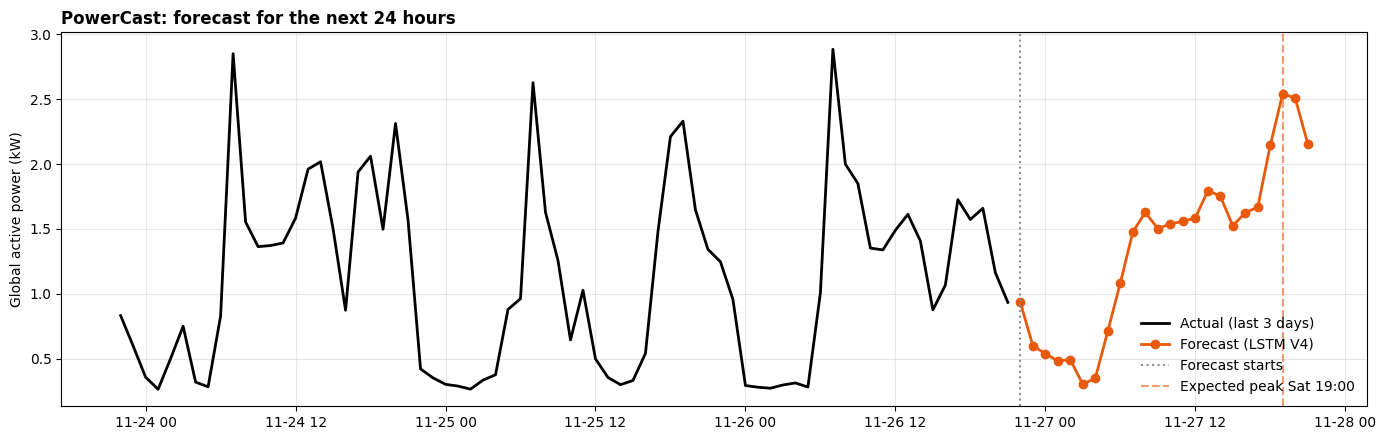

In [ ]:
import sys, importlib
sys.path.append(BASE)
import predict
importlib.reload(predict)                      # load the latest version
from predict import predict_next_24h, make_future_features

last_hour = df.index[-1]
forecast_start = last_hour + pd.Timedelta(hours=1)
history = df[TARGET].iloc[-HISTORY:]           # the last 7 days we really know
print(f'Last known hour: {last_hour:%A %d %b %Y, %H:%M}')
print(f'Forecast:        {forecast_start:%A %d %b %H:%M} → {forecast_start + pd.Timedelta(hours=HORIZON - 1):%A %d %b %H:%M}')

future = make_future_features(forecast_start)              # steps 1-3: 24 rows, calendar only
future['forecast (kW)'] = predict_next_24h(history, forecast_start)   # steps 4-5
display(future.round(3))

peak_time = future['forecast (kW)'].idxmax()
print(f'Expected peak: {peak_time:%A %H:00} ({future["forecast (kW)"].max():.2f} kW) | '
      f'Expected total: {future["forecast (kW)"].sum():.1f} kWh')

recent = df[TARGET].iloc[-72:]
plt.figure(figsize=(14, 4.5))
plt.plot(recent.index, recent.values, color='black', lw=2, label='Actual (last 3 days)')
plt.plot(future.index, future['forecast (kW)'], color='#E8590C', lw=2, marker='o', label=f'Forecast ({FINAL})')
plt.axvline(forecast_start, color='#868E96', ls=':', label='Forecast starts')
plt.axvline(peak_time, color='#E8590C', ls='--', alpha=0.6, label=f'Expected peak {peak_time:%a %H:00}')
plt.title('PowerCast: forecast for the next 24 hours', loc='left', fontweight='bold')
plt.ylabel('Global active power (kW)')
plt.legend(frameon=False); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f'{FIG}/final_next_24h_forecast.png', dpi=200, bbox_inches='tight')
plt.show()

### 7c. Demo day with the real values (19 Nov 2010)
The same function on a test day where we know what really happened, to compare the forecast with the actual consumption.

predict.py gives the same forecast as the evaluated model: True
Predicted peak: 20:00 | Actual peak: 07:00
MAE this day: 0.39 kW (average on test: 0.41 kW)
Predicted total: 30.7 kWh | Actual total: 26.2 kWh


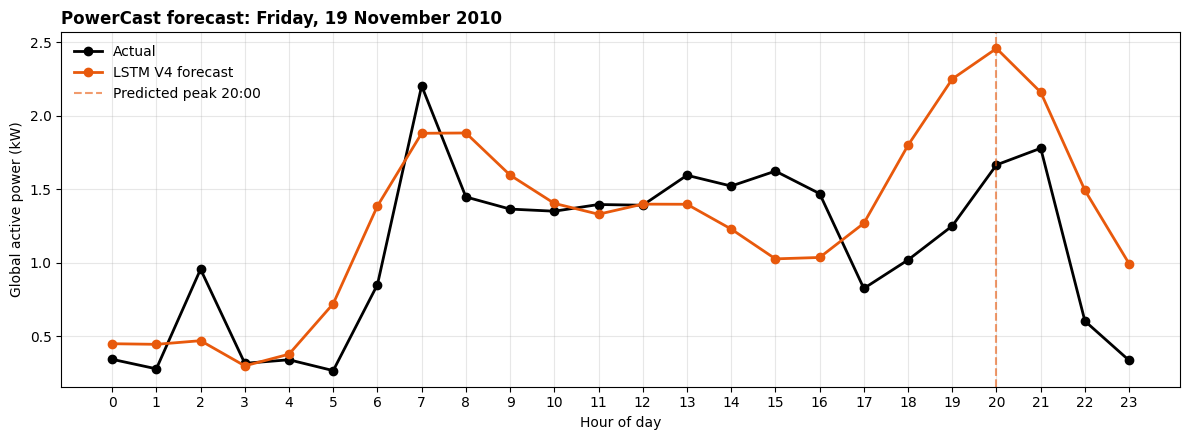

In [ ]:
DEMO_DAY = pd.Timestamp('2010-11-19')
s = df.index.get_loc(DEMO_DAY)
history = df[TARGET].iloc[s - HISTORY:s]
actual = df[TARGET].iloc[s:s + HORIZON].to_numpy()
forecast = predict_next_24h(history)           # Series with dates -> calendar features are built automatically

same = np.allclose(forecast, lstm_predict(LSTMS[FINAL], [s])[0], atol=1e-3)
print('predict.py gives the same forecast as the evaluated model:', same)

test_mae = mean_absolute_error(Y_test.ravel(), test_preds[FINAL_LABEL].ravel())
peak_f, peak_a = forecast.argmax(), actual.argmax()
print(f'Predicted peak: {peak_f:02d}:00 | Actual peak: {peak_a:02d}:00')
print(f'MAE this day: {np.abs(actual - forecast).mean():.2f} kW (average on test: {test_mae:.2f} kW)')
print(f'Predicted total: {forecast.sum():.1f} kWh | Actual total: {actual.sum():.1f} kWh')

plt.figure(figsize=(12, 4.5))
plt.plot(range(24), actual, color='black', lw=2, marker='o', label='Actual')
plt.plot(range(24), forecast, color='#E8590C', lw=2, marker='o', label=f'{FINAL} forecast')
plt.axvline(peak_f, color='#E8590C', ls='--', alpha=0.6, label=f'Predicted peak {peak_f:02d}:00')
plt.title(f'PowerCast forecast: {DEMO_DAY:%A, %d %B %Y}', loc='left', fontweight='bold')
plt.xlabel('Hour of day')
plt.ylabel('Global active power (kW)')
plt.xticks(range(24))
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f'{FIG}/final_demo_2010-11-19.png', dpi=200, bbox_inches='tight')
plt.show()

## 8. Results Summary, Limitations & Conclusion

### 8a. Final numbers
Computed from the tables above, so they always match the latest run.

In [ ]:
from IPython.display import Markdown

def mae(Y, P):
    return mean_absolute_error(Y.ravel(), P.ravel())

baselines = ['Last-value', 'Seasonal Naive', 'Weekly Naive']
bv = min(baselines, key=lambda n: mae(Y_val, val_preds[n]))
bt = min(baselines, key=lambda n: mae(Y_test, test_preds[n]))
fv, ft = mae(Y_val, val_preds[FINAL_LABEL]), mae(Y_test, test_preds[FINAL_LABEL])
r2v = r2_score(Y_val.ravel(), val_preds[FINAL_LABEL].ravel())
r2t = r2_score(Y_test.ravel(), test_preds[FINAL_LABEL].ravel())
pk = err_table.set_index('Model').loc[FINAL_LABEL]

display(Markdown(f"""
| | Validation | Test |
|---|---|---|
| Final model | **{FINAL}** | **{FINAL}** |
| MAE (kW) | **{fv:.3f}** | **{ft:.3f}** |
| Best baseline MAE (kW) | {mae(Y_val, val_preds[bv]):.3f} ({bv}) | {mae(Y_test, test_preds[bt]):.3f} ({bt}) |
| Improvement vs best baseline | {100 * (1 - fv / mae(Y_val, val_preds[bv])):.0f}% | {100 * (1 - ft / mae(Y_test, test_preds[bt])):.0f}% |
| R² | {r2v:+.2f} | {r2t:+.2f} |

**Peak hour (validation):** exact on {pk['Peak hour exact (%)']:.0f}% of days, ±1h on {pk['Peak hour ±1h (%)']:.0f}%. **Peaks:** bias on the top 25% hours = {pk['Bias high hours (kW)']:+.2f} kW.
"""))


| | Validation | Test |
|---|---|---|
| Final model | **LSTM V4** | **LSTM V4** |
| MAE (kW) | **0.464** | **0.409** |
| Best baseline MAE (kW) | 0.580 (Weekly Naive) | 0.479 (Seasonal Naive) |
| Improvement vs best baseline | 20% | 15% |
| R² | +0.39 | +0.35 |

**Peak hour (validation):** exact on 19% of days, ±1h on 40%. **Peaks:** bias on the top 25% hours = -0.67 kW.


### Limitations
- **One household only**: results may not generalize to other homes.
- **No external data**: weather, holidays and household absence are not in the data. Example: **August 2008 drops to 0.28 kW** (vs about 0.7 kW in other years), probably because the family was away. No model can predict that from past consumption alone.
- **Peaks are under-predicted**: the LSTM gives a smoother forecast and misses the highest spikes (bias −0.67 kW on the top 25% hours). The **peak-hour alert is approximate**: exact on 19% of validation days, ±1h on 40%. Example: on the demo day the real peak came in the morning (07:00), while the model expected the usual evening peak.
- **Test period used more than once**: baselines and LSTM V1 were evaluated on test before V2–V5 were added. The final model was still chosen on validation only.
- **Missing data**: 421 hours (1.2%) were filled; the longest gap was about 5 days.

### Conclusion
- We forecast a household's hourly electricity use for the next 24 hours from the previous 7 days and the calendar of the forecast day.
- Simple baselines were hard to beat: **Weekly Naive** (MAE 0.580 kW on validation) beat our first LSTM (0.720).
- Following the TA's feedback, step by step: calendar features (V2), a window at every hour (V3), the **calendar of the next 24 hours** as a second input (V4) and the season of the year (V5, no gain).
- **LSTM V4** is our final model: **MAE 0.464 kW on validation** (−20% vs the best baseline) and **0.409 kW on test** (−15% vs the best baseline), with a positive R² (+0.35 on test).
- The model can forecast a **day it has never seen** (section 7b): it only needs the last 168 hours and the calendar of the next 24 hours, with no leakage.
- **Main learning:** always compare with a simple baseline. More training windows and the right features mattered more than a bigger model.
- **Next steps:** add holiday and weather data, and give more weight to peak hours during training.

---

## ⚡ PowerCast in one line
**An LSTM that reads the last 7 days of consumption and knows the calendar of the next 24 hours forecasts this household's next day with an average error of 0.41 kW on test, 15–20% better than simple baselines.**

**Files:** `data/hourly_clean.csv` · `models/powercast_lstm_final.keras` · `figures/` · `predict.py` · `app.py` (Streamlit dashboard)

**Team:** Rana Aljumayi · Salwa · Renad Alotaibi · Raneem Alghamdi | Le Wagon Data Science #2344

*Thank you!* 🙏